# Evaluation demo

I compare the saved headline metrics and draw both ROC curves on held-out data.

In [1]:
from pathlib import Path
import json
import os
import sys

# Load evaluation outputs instead of repeating the bootstrap calculations.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_curve
from data import load
from model import Scorer

evaluation = json.loads((ROOT / "reports/evaluation.json").read_text())
sets = {"test": load("test"), "external": load("external_test")}

In [2]:
# Put the operating-point metrics beside AUC for each model and data set.
headline = []
for model_name in ("baseline", "advanced"):
    for set_name in ("test", "external"):
        report = evaluation[model_name][set_name]
        operating_point = report["at_threshold"]
        headline.append({
            "model": model_name, "set": set_name,
            "auc": report["roc_auc"], "auc_ci": report["roc_auc_ci"],
            "recall_at_1pct_fpr": report["recall_at_1pct_fpr"],
            "threshold": evaluation[model_name]["threshold"],
            "recall": operating_point["recall"], "fpr": operating_point["fpr"],
            "precision": operating_point["precision"],
            "deployed_precision": operating_point["deployed_precision"],
        })
display(pd.DataFrame(headline))

,model,set,auc,auc_ci,recall_at_1pct_fpr,threshold,recall,fpr,precision,deployed_precision
0,baseline,test,0.9785,"[0.9726, 0.9835]",0.7593,0.7996,0.7551,0.0098,0.9872,0.0716
1,baseline,external,0.9443,"[0.9355, 0.953]",0.6858,0.7996,0.3681,0.0000,1.0000,1.0000
2,advanced,test,0.9867,"[0.982, 0.9907]",0.8286,0.9709,0.7950,0.0063,0.9921,0.1122
3,advanced,external,0.9066,"[0.8943, 0.9185]",0.6585,0.9709,0.4577,0.0000,1.0000,1.0000


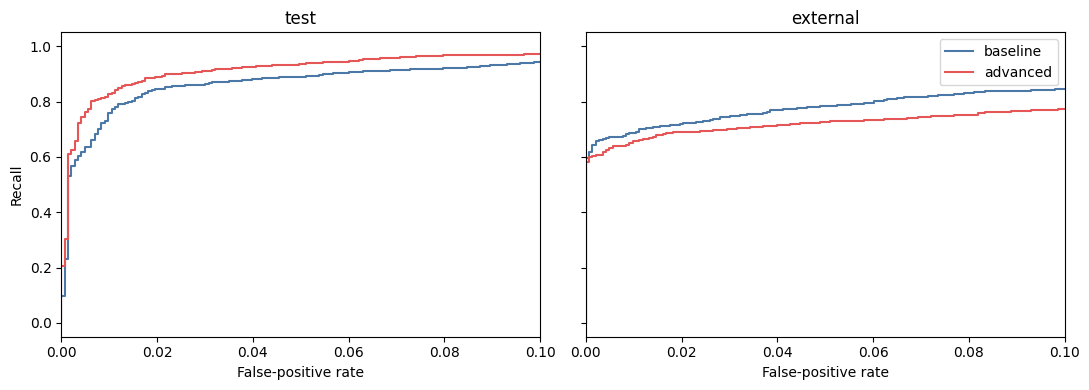

In [3]:
# Score each held-out set with the exported ONNX models.
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for axis, set_name in zip(axes, ("test", "external")):
    frame = sets[set_name]
    for model_name, color in (("baseline", "#4c78a8"), ("advanced", "#e45756")):
        probability = Scorer(model_name).predict_proba(frame.url)
        fpr, tpr, _ = roc_curve(frame.label, probability)
        axis.plot(fpr, tpr, label=model_name, color=color)
    axis.set(title=set_name, xlabel="False-positive rate", xlim=(0, 0.1))
axes[0].set_ylabel("Recall")
axes[-1].legend()
fig.tight_layout()
plt.show()
plt.close(fig)

I zoom in on the low-FPR region because that is where this review-queue model is meant to operate.